<a href="https://colab.research.google.com/github/Renyambar/Reny_MachineLearning/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Hierarchical Clustering pada Customer Credit Card

##Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

##Membaca Dataset

In [2]:
# Pastikan CC_Customer_Dataset.csv sudah di-upload ke sesi Google Colab.
df = pd.read_csv("CC_Customer_Dataset.csv")

print("Ukuran dataset:", df.shape)
display(df.head())
print("\nNama kolom:")
print(df.columns.tolist())
print("\nMissing value tiap kolom:")
display(df.isnull().sum())

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3



Nama kolom:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Missing value tiap kolom:


,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


##Memilih seluruh variabel yang dapat digunakan

In [3]:
# Gunakan semua fitur numerik yang menggambarkan karakteristik pelanggan.
# Identifier dikecualikan karena tidak merepresentasikan perilaku/karakteristik pelanggan.
feature_cols = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

X_df = df[feature_cols].copy()

# Jika terdapat nilai kosong, isi dengan median kolom terkait.
X_df = X_df.fillna(X_df.median(numeric_only=True))

print("Fitur yang digunakan:")
print(feature_cols)
display(X_df.head())

Fitur yang digunakan:
['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


##Standarisasi Fitur


In [4]:
# Standardisasi diperlukan karena skala Avg_Credit_Limit jauh berbeda
# dari jumlah kartu, kunjungan, dan panggilan.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

print("Ukuran data setelah standardisasi:", X_scaled.shape)
print("Rata-rata fitur terstandardisasi (mendekati 0):")
print(np.round(X_scaled.mean(axis=0), 3))
print("Standar deviasi (mendekati 1):")
print(np.round(X_scaled.std(axis=0), 3))

Ukuran data setelah standardisasi: (660, 5)
Rata-rata fitur terstandardisasi (mendekati 0):
[ 0.  0. -0.  0. -0.]
Standar deviasi (mendekati 1):
[1. 1. 1. 1. 1.]


##Dendrogram untuk melihat struktur hierarki

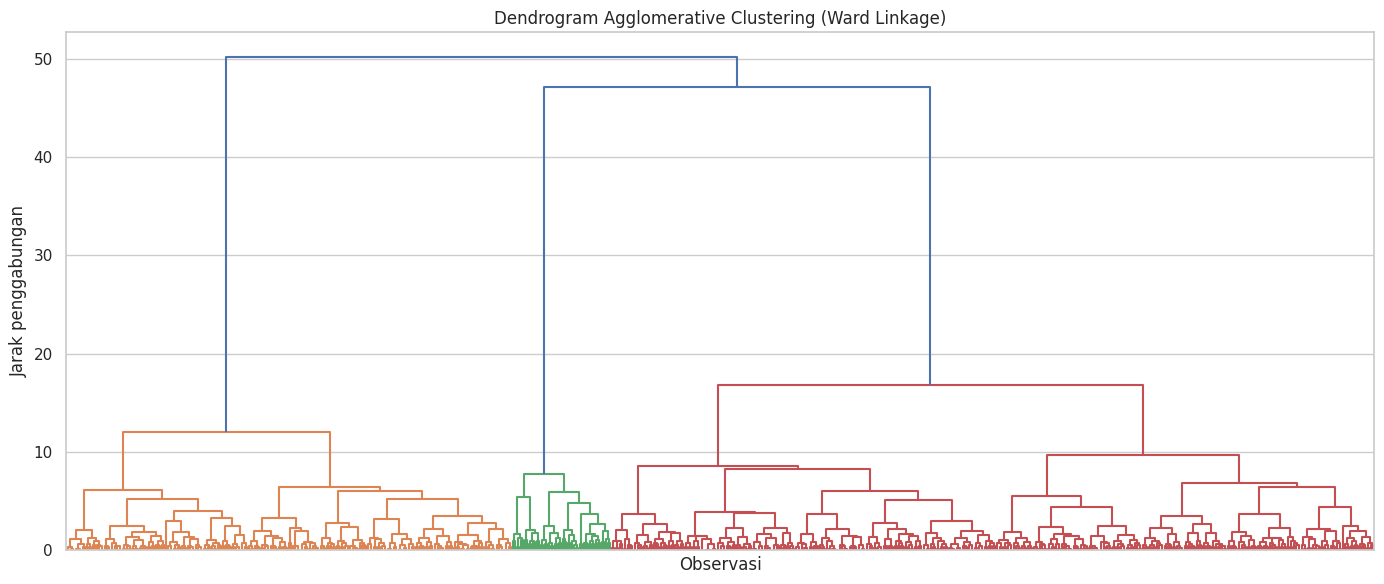

In [5]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True, color_threshold=None)
plt.title("Dendrogram Agglomerative Clustering (Ward Linkage)")
plt.xlabel("Observasi")
plt.ylabel("Jarak penggabungan")
plt.tight_layout()
plt.show()

##Membandingkan jumlah cluster

,Jumlah Cluster (k),Silhouette Score,DBI
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851
4,6,0.2268,1.4109
5,7,0.2163,1.4394
6,8,0.2187,1.4489
7,9,0.1953,1.5466
8,10,0.1931,1.5537


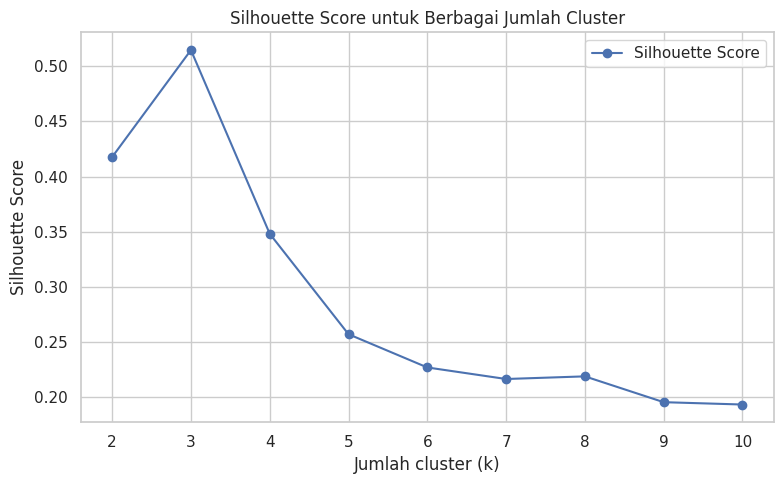

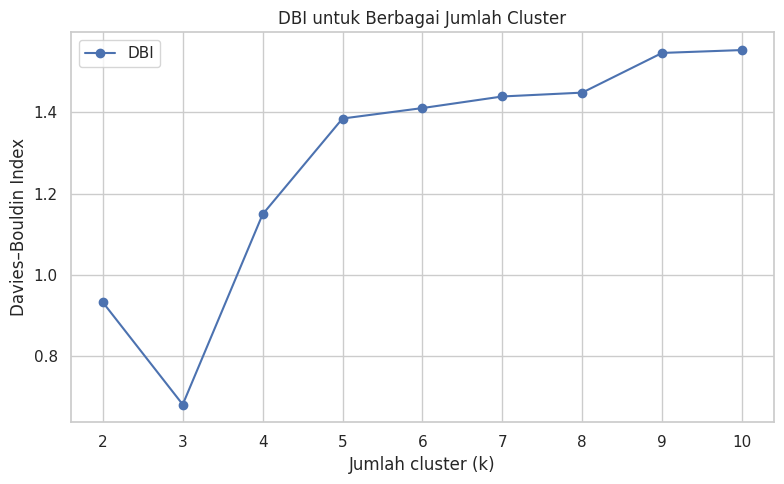

k dengan Silhouette Score tertinggi: 3
k dengan DBI terendah: 3


In [6]:
k_values = range(2, 11)
metric_results = []

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)

    metric_results.append({
        "Jumlah Cluster (k)": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "DBI": davies_bouldin_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(metric_results)
display(metrics_df.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(metrics_df["Jumlah Cluster (k)"], metrics_df["Silhouette Score"],
        marker="o", label="Silhouette Score")
ax.set_xlabel("Jumlah cluster (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Silhouette Score untuk Berbagai Jumlah Cluster")
ax.set_xticks(list(k_values))
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(metrics_df["Jumlah Cluster (k)"], metrics_df["DBI"],
        marker="o", label="DBI")
ax.set_xlabel("Jumlah cluster (k)")
ax.set_ylabel("Davies–Bouldin Index")
ax.set_title("DBI untuk Berbagai Jumlah Cluster")
ax.set_xticks(list(k_values))
ax.legend()
plt.tight_layout()
plt.show()

best_silhouette_k = int(metrics_df.loc[metrics_df["Silhouette Score"].idxmax(), "Jumlah Cluster (k)"])
best_dbi_k = int(metrics_df.loc[metrics_df["DBI"].idxmin(), "Jumlah Cluster (k)"])
print("k dengan Silhouette Score tertinggi:", best_silhouette_k)
print("k dengan DBI terendah:", best_dbi_k)

##Membuat model Agglomerative Clustering final

In [7]:
n_clusters_final = 3

agg_model = AgglomerativeClustering(
    n_clusters=n_clusters_final,
    linkage="ward"
)
df["Cluster"] = agg_model.fit_predict(X_scaled)

print("Jumlah cluster:", df["Cluster"].nunique())
print("\nJumlah pelanggan pada setiap cluster:")
display(df["Cluster"].value_counts().sort_index().rename("Jumlah Pelanggan").to_frame())

print("\nRata-rata fitur tiap cluster:")
display(df.groupby("Cluster")[feature_cols].mean().round(2))

Jumlah cluster: 3

Jumlah pelanggan pada setiap cluster:


,Jumlah Pelanggan
Cluster,
0,385
1,225
2,50



Rata-rata fitur tiap cluster:


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08


##Scatterplot hasil cluster berdasarkan dua fitur

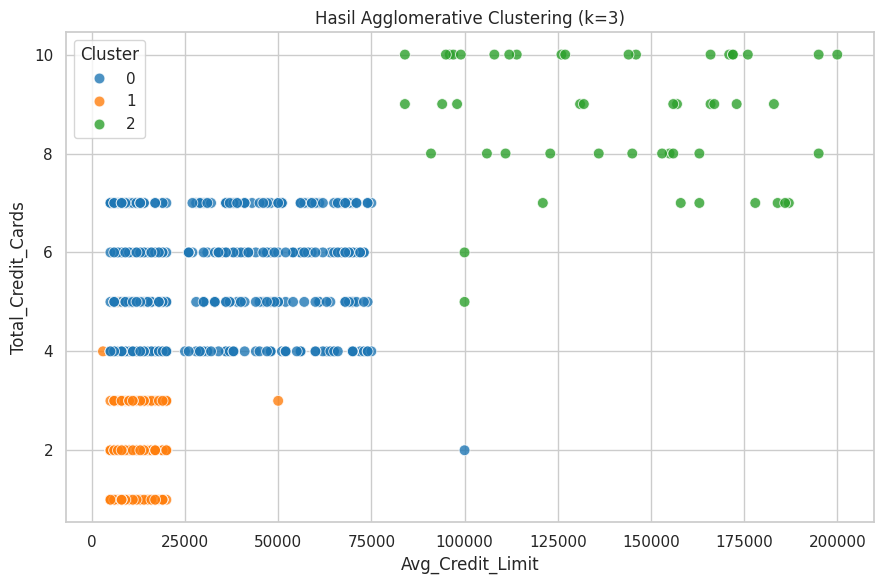

In [8]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Avg_Credit_Limit",
    y="Total_Credit_Cards",
    hue="Cluster",
    palette="tab10",
    s=60,
    alpha=0.8
)
plt.title(f"Hasil Agglomerative Clustering (k={n_clusters_final})")
plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_Credit_Cards")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

##Evaluasi Silhouette Score dan DBI

In [9]:
labels_final = df["Cluster"].to_numpy()

sil_score = silhouette_score(X_scaled, labels_final)
dbi_score = davies_bouldin_score(X_scaled, labels_final)

print(f"Silhouette Score : {sil_score:.4f}")
print(f"DBI              : {dbi_score:.4f}")

print("\nInterpretasi:")
if sil_score > 0.5:
    print("- Silhouette Score menunjukkan cluster relatif terpisah dengan baik.")
elif sil_score > 0.25:
    print("- Silhouette Score menunjukkan struktur cluster cukup terlihat, tetapi masih ada tumpang tindih.")
else:
    print("- Silhouette Score menunjukkan pemisahan cluster lemah.")

print("- Untuk perbandingan model, Silhouette Score yang lebih tinggi umumnya lebih baik.")
print("- Untuk perbandingan model, DBI yang lebih rendah umumnya lebih baik.")

Silhouette Score : 0.5148
DBI              : 0.6810

Interpretasi:
- Silhouette Score menunjukkan cluster relatif terpisah dengan baik.
- Untuk perbandingan model, Silhouette Score yang lebih tinggi umumnya lebih baik.
- Untuk perbandingan model, DBI yang lebih rendah umumnya lebih baik.
